#  Hands-on 3: Redes Neuronales - Perceptrón Multicapa (MLP) con Scikit-Learn

**Materia:** Deep Learning  
**Integrantes:** Iker Gael Rico Nonato 
  Luis Eduardo Navarro Hernandez 


---

## 1. Fundamentos Teóricos del Perceptrón Multicapa (MLP)

Un **Perceptrón Multicapa (Multilayer Perceptron - MLP)** es una arquitectura de red neuronal artificial de tipo *feedforward* (propagación hacia adelante) diseñada para resolver problemas de clasificación y regresión no lineales.

A diferencia del **Perceptrón Simple**, que solo posee una capa de entrada y una neurona de salida (capaz de resolver únicamente problemas linealmente separables como la compuerta AND u OR), el MLP incorpora una o más **capas ocultas** (*hidden layers*).

### Estructura general de un MLP:
1. **Capa de Entrada (Input Layer):** Recibe las características de entrada $x_1, x_2, \dots, x_n$ del dataset.
2. **Capas Ocultas (Hidden Layers):** Compuestas por capas intermedias de neuronas. Cada neurona aplica una combinación lineal seguida de una **función de activación no lineal** (ej. ReLU, Sigmoide, Tanh), lo que permite a la red 'doblar' el espacio geométrico y aprender fronteras de decisión complejas.
3. **Capa de Salida (Output Layer):** Genera las predicciones finales (por ejemplo, probabilidades o etiquetas de clase para la clasificación de las especies de la flor Iris).

## 2. Modelo Matemático del MLP

El procesamiento dentro de cada neurona de la red neuronal se descompone en tres componentes matemáticos clave:

### A. Combinación Lineal (Suma Ponderada)
Para una neurona $j$ en la capa $l$, la combinación lineal $z_j^{[l]}$ de las entradas activadas de la capa anterior $a^{[l-1]}$ viene dada por:
$$z_j^{[l]} = \sum_{i=1}^{m} w_{ji}^{[l]} a_i^{[l-1]} + b_j^{[l]}$$
En notación matricial para la capa completa:
$$Z^{[l]} = W^{[l]} A^{[l-1]} + b^{[l]}$$
donde $W^{[l]}$ es la matriz de pesos y $b^{[l]}$ es el vector de sesgos (*biases*).

### B. Función de Activación No Lineal
La combinación lineal $z$ pasa a través de una función de activación no lineal $\sigma(z)$ para generar la salida $a$ de la neurona:
$$a^{[l]} = \sigma(Z^{[l]})$$
En las capas ocultas de este tutorial utilizamos **ReLU (Rectified Linear Unit)**:
$$\text{ReLU}(z) = \max(0, z)$$

### C. Propagación Hacia Atrás (Backpropagation) y Optimizador Adam
El entrenamiento del MLP se basa en evaluar el error entre las predicciones $\hat{y}$ y las etiquetas reales $y$ mediante una función de pérdida (Entropía Cruzada). Usando la regla de la cadena del cálculo multivariable (**Backpropagation**), la red calcula los gradientes del error respecto a cada peso $\frac{\partial E}{\partial w}$.

Posteriormente, el optimizador **Adam (Adaptive Moment Estimation)** actualiza los pesos iterativamente para minimizar la función de pérdida.

## 3. Importación de Librerías

In [ ]:
# Importación de paquetes esenciales para el manejo de matrices, tablas y gráficos
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Carga del dataset Iris desde Scikit-Learn
from sklearn.datasets import load_iris

# Módulos de Scikit-Learn para preparación de datos
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Clasificador de Red Neuronal (Perceptrón Multicapa)
from sklearn.neural_network import MLPClassifier

# Métricas para evaluación del desempeño del modelo
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.inspection import DecisionBoundaryDisplay

print(" Librerías e identificadores inicializados con éxito.")

 Librerías e identificadores inicializados con éxito.


## 4. Pipeline de Machine Learning

### Etapa i: Selección de los patrones para entrenamiento (Dataset) y Scatter Plot

En esta primera etapa cargamos el clásico **Dataset Iris**, el cual contiene 150 muestras de flores Iris distribuidas equitativamente en 3 especies (*setosa*, *versicolor*, *virginica*).
Cada muestra cuenta con 4 características continuas:
1. `sepal length (cm)`: Longitud del sépalo
2. `sepal width (cm)`: Ancho del sépalo
3. `petal length (cm)`: Longitud del pétalo
4. `petal width (cm)`: Ancho del pétalo

--- PRIMERAS 5 FILAS DEL DATASET IRIS ---
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

  species  
0  setosa  
1  setosa  
2  setosa  
3  setosa  
4  setosa  

--- CONTEO DE MUESTRAS POR CLASE ---
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


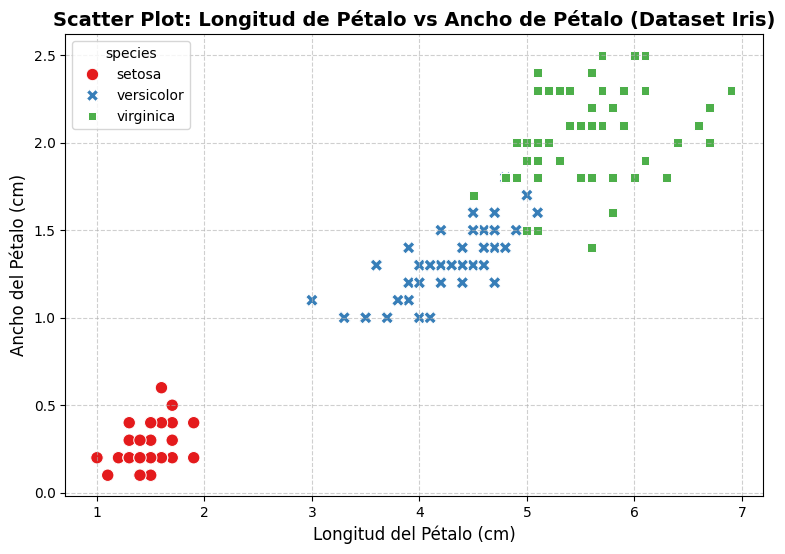

In [ ]:
# Carga del conjunto de datos Iris desde Scikit-Learn
iris = load_iris()
X = iris.data
Y = iris.target
feature_names = iris.feature_names
target_names = iris.target_names

# Creación del DataFrame de Pandas para exploración rápida
iris_df = pd.DataFrame(X, columns=feature_names)
iris_df['species'] = [target_names[i] for i in Y]

print("--- PRIMERAS 5 FILAS DEL DATASET IRIS ---")
print(iris_df.head())

print("\n--- CONTEO DE MUESTRAS POR CLASE ---")
print(iris_df['species'].value_counts())

# Generación del Scatter Plot para inspeccionar los patrones visualmente
plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=iris_df,
    x='petal length (cm)',
    y='petal width (cm)',
    hue='species',
    palette='Set1',
    s=80,
    style='species'
)
plt.title("Scatter Plot: Longitud de Pétalo vs Ancho de Pétalo (Dataset Iris)", fontsize=14, fontweight='bold')
plt.xlabel("Longitud del Pétalo (cm)", fontsize=12)
plt.ylabel("Ancho del Pétalo (cm)", fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

### Etapa ii: Preprocesamiento (Splitting & Scaling)

El preprocesamiento adecuado garantiza un entrenamiento óptimo de la red neuronal:
1. **Splitting:** Dividimos los datos en 80% para entrenamiento (`X_train`, `Y_train`) y 20% para prueba (`X_test`, `Y_test`).
2. **Scaling:** Escalamos las características utilizando `StandardScaler` (z-score normalization: media=0, varianza=1). Las redes neuronales son sumamente sensibles a las diferencias en la magnitud de las entradas.

In [ ]:
# 1. Splitting: División estratificada (preserva la proporción de clases)
X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y,
    test_size=0.20,      # 20% reservado para prueba
    random_state=42,     # Semilla fija para reproducibilidad
    stratify=Y           # Balance estratificado entre clases
)

# 2. Scaling: Estandarización de los datos de entrada
scaler = StandardScaler()

# Calculamos la media/std únicamente con los datos de entrenamiento para prevenir fuga de datos
X_train_scaled = scaler.fit_transform(X_train)

# Aplicamos exactamente la misma escala al conjunto de prueba
X_test_scaled = scaler.transform(X_test)

print(f" Datos procesados con éxito.")
print(f"Muestras de Entrenamiento: {X_train_scaled.shape[0]} | Muestras de Prueba: {X_test_scaled.shape[0]}")

 Datos procesados con éxito.
Muestras de Entrenamiento: 120 | Muestras de Prueba: 30


### Etapa iii: Selección de Modelo y Entrenamiento

A través de la clase `MLPClassifier` de Scikit-Learn, instanciamos la arquitectura de la red neuronal:
- **`hidden_layer_sizes=(10, 10)`:** Red con 2 capas ocultas compuestas de 10 neuronas cada una.
- **`activation='relu'`:** Rectificador lineal unitario en capas ocultas.
- **`solver='adam'`:** Optimizador inteligente de descenso de gradiente estocástico.
- **`max_iter=1000`:** Número máximo de épocas permitidas para la convergencia.
- **`random_state=42`:** Inicialización reproducible de pesos y sesgos.

In [ ]:
# Instanciación del clasificador MLP
mlp_model = MLPClassifier(
    hidden_layer_sizes=(10, 10), # Configuración de 2 capas ocultas de 10 neuronas
    activation='relu',           # Función de activación no lineal ReLU
    solver='adam',               # Optimizador Adam
    max_iter=1000,               # Épocas máximas de entrenamiento
    random_state=42              # Semilla determinista
)

# Entrenamiento de la red mediante propagación directa y Backpropagation
print("Entrenando la red neuronal Perceptrón Multicapa...")
mlp_model.fit(X_train_scaled, Y_train)

print(f" Entrenamiento completado exitosamente en {mlp_model.n_iter_} iteraciones.")

Entrenando la red neuronal Perceptrón Multicapa...
 Entrenamiento completado exitosamente en 603 iteraciones.


### Etapa iv: Evaluación del Modelo (Metrics & Matriz de Confusión)

Evaluamos la capacidad de generalización del modelo sobre el conjunto de prueba (`X_test_scaled`), calculando la exactitud global (*Accuracy*), la Matriz de Confusión y el Reporte de Clasificación detallado (*Precision*, *Recall*, *F1-Score*).

 Exactitud Global (Accuracy) del MLP: 96.67%


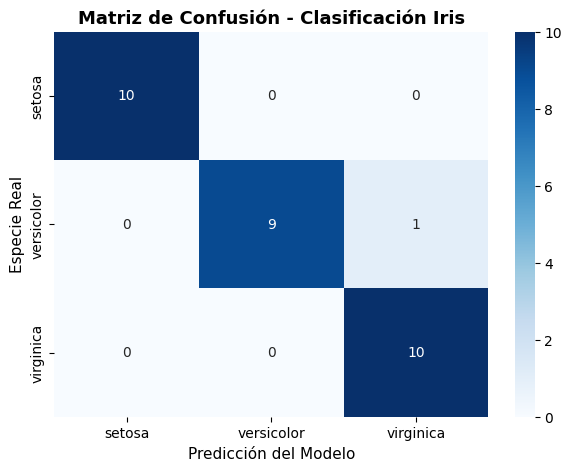

--- REPORTE DE CLASIFICACIÓN COMPLETO ---
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



In [ ]:
# Inferencia sobre el conjunto de prueba no visto
predictions = mlp_model.predict(X_test_scaled)

# Cálculo de la Exactitud Global (Accuracy)
acc = accuracy_score(Y_test, predictions)
print(f" Exactitud Global (Accuracy) del MLP: {acc * 100:.2f}%")

# Generación y visualización de la Matriz de Confusión
conf_matrix = confusion_matrix(Y_test, predictions)

plt.figure(figsize=(7, 5))
sns.heatmap(
    conf_matrix,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=target_names,
    yticklabels=target_names
)
plt.title("Matriz de Confusión - Clasificación Iris", fontsize=13, fontweight='bold')
plt.xlabel("Predicción del Modelo", fontsize=11)
plt.ylabel("Especie Real", fontsize=11)
plt.show()

# Impresión del reporte analítico de clasificación
print("--- REPORTE DE CLASIFICACIÓN COMPLETO ---")
print(classification_report(Y_test, predictions, target_names=target_names))

### 5. Visualización de la Frontera de Decisión No Lineal

Para visualizar cómo el Perceptrón Multicapa 'dobla' el plano de decisión para separar las clases, entrenamos un modelo idéntico utilizando únicamente dos características (`petal length` y `petal width`) y dibujamos sus regiones de decisión con `DecisionBoundaryDisplay`.

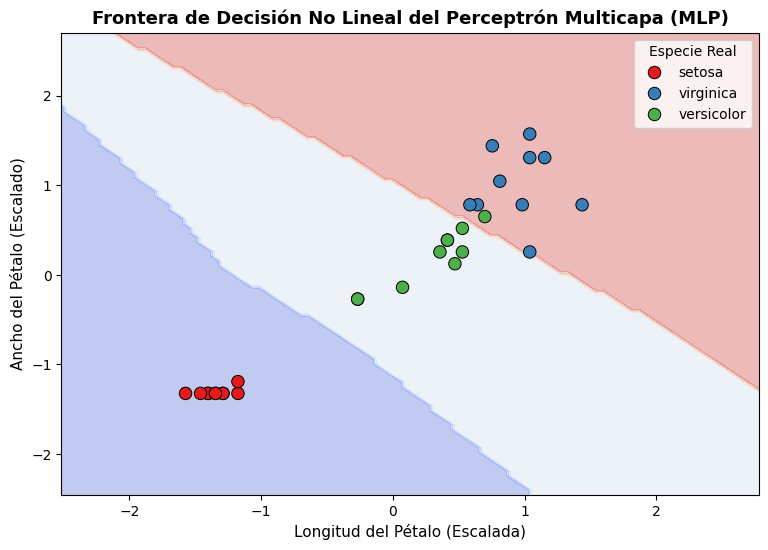

In [ ]:
# Seleccionamos únicamente las dos características del pétalo para poder graficar en 2D
X_train_2d = X_train_scaled[:, 2:4]
X_test_2d = X_test_scaled[:, 2:4]

# Reentrenamos el modelo MLP exclusivamente con estas 2 dimensiones
mlp_2d = MLPClassifier(hidden_layer_sizes=(10, 10), max_iter=1000, activation='relu', solver='adam', random_state=42)
mlp_2d.fit(X_train_2d, Y_train)

# Dibujamos la frontera de decisión en 2D
plt.figure(figsize=(9, 6))
disp = DecisionBoundaryDisplay.from_estimator(
    mlp_2d,
    X_train_2d,
    response_method='predict',
    cmap=plt.cm.coolwarm,
    alpha=0.35,
    ax=plt.gca()
)

# Superponemos los puntos de prueba
sns.scatterplot(
    x=X_test_2d[:, 0],
    y=X_test_2d[:, 1],
    hue=[target_names[i] for i in Y_test],
    palette='Set1',
    edgecolor='k',
    s=80
)
plt.title("Frontera de Decisión No Lineal del Perceptrón Multicapa (MLP)", fontsize=13, fontweight='bold')
plt.xlabel("Longitud del Pétalo (Escalada)", fontsize=11)
plt.ylabel("Ancho del Pétalo (Escalado)", fontsize=11)
plt.legend(title="Especie Real")
plt.show()